CMSC320 Project Checkpoint 2

Names: Ena Song, Olexiy (Alex) Slokvenko, Alan Deng, Andrew Li,  Noah Combatir, Aditya Agrawal

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("data/spotify_data clean.csv")

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (8582, 15)


,track_id,track_name,track_number,track_popularity,explicit,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_release_date,album_total_tracks,album_type,track_duration_min
0,3EJS5LyekDim1Tf5rBFmZl,Trippy Mane (ft. Project Pat),4,0,True,Diplo,77,2812821,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.55
1,1oQW6G2ZiwMuHqlPpP27DB,OMG!,1,0,True,Yelawolf,64,2363438,"country hip hop, southern hip hop",4SUmmwnv0xTjRcLdjczGg2,OMG!,2025-10-31,1,single,3.07
2,7mdkjzoIYlf1rx9EtBpGmU,Hard 2 Find,1,4,True,Riff Raff,48,193302,NaN,3E3zEAL8gUYWaLYB9L7gbp,Hard 2 Find,2025-10-31,1,single,2.55
3,67rW0Zl7oB3qEpD5YWWE5w,Still Get Like That (ft. Project Pat & Starrah),8,30,True,Diplo,77,2813710,moombahton,5QRFnGnBeMGePBKF2xTz5z,"d00mscrvll, Vol. 1",2025-10-31,9,album,1.69
4,15xptTfRBrjsppW0INUZjf,ride me like a harley,2,0,True,Rumelis,48,8682,dark r&b,06FDIpSHYmZAZoyuYtc7kd,come closer / ride me like a harley,2025-10-30,2,single,2.39


In [14]:
num_cols = ['track_popularity', 'artist_popularity', 'artist_followers', 'album_total_tracks', 'track_duration_min']

#summary statistics
print("--- Numerical Feature Summary Statistics ---")
display(df[num_cols].describe())

--- Numerical Feature Summary Statistics ---


,track_popularity,artist_popularity,artist_followers,album_total_tracks,track_duration_min
count,8582.000000,8582.000000,8.582000e+03,8582.000000,8582.000000
mean,52.356211,69.730016,2.403472e+07,13.789443,3.492805
std,23.816076,19.645979,3.803180e+07,11.887131,1.057970
min,0.000000,0.000000,0.000000e+00,1.000000,0.070000
25%,39.000000,60.000000,4.623200e+05,6.000000,2.880000
50%,58.000000,74.000000,6.105547e+06,13.000000,3.445000
75%,71.000000,84.000000,2.725255e+07,17.000000,3.990000
max,99.000000,100.000000,1.455421e+08,181.000000,13.510000


Pearson Correlation (Artist vs Track Popularity): r = 0.4669, p-value = 0.0000e+00


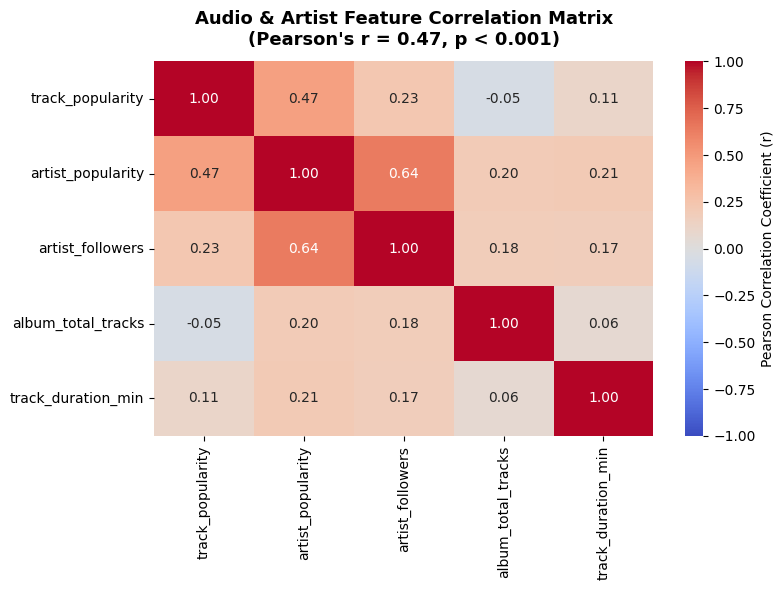

In [17]:
#pearson correlation matrix
corr_matrix = df[num_cols].corr()

#significance test between artist popularity and track popularity
r_val, p_val = stats.pearsonr(df['artist_popularity'], df['track_popularity'])
print(f"Pearson Correlation (Artist vs Track Popularity): r = {r_val:.4f}, p-value = {p_val:.4e}")

#Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Pearson Correlation Coefficient (r)'}
)
plt.title("Audio & Artist Feature Correlation Matrix\n(Pearson's r = 0.47, p < 0.001)", fontsize=13, pad=12, fontweight='bold')
plt.tight_layout()

#Save image
plt.savefig("correlation_matrix.png", dpi=300)
plt.show()

Conclusion from correlation heatmap: An artist's overall platform standing (artist_popularity) is the primary numeric feature associated with higher individual song popularity ($r = 0.47$). Conversely, metadata features like track duration and total album track count show virtually no linear association with song performance, highlighting that artist branding and audience reach drive track success far more than structural song parameters.